# 05 · Run-to-run variability — seeds 0–4 (FD001)

Steps 4 and 5 are repeated for five seeds. The seed changes (i) which engines land in the
train / calibration / internal-test sets and (ii) LightGBM's row and column subsampling. Every
official-test result is logged to `results/runs.csv` (one row per subset, model and seed).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import CONFIDENCE_LEVEL
from src.experiment import run_seed
from src.results import load_runs
from src.plots import save

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

SEEDS = [0, 1, 2, 3, 4]
tables = []
for seed in SEEDS:
    res = run_seed("FD001", seed=seed, log=True)
    tables.append(pd.concat([res["point_table"], res["interval_table"]]).assign(seed=seed))
runs = pd.concat(tables, ignore_index=True)
runs.head()

,model,eval_set,rmse,nasa_score,n,coverage,mean_width,seed
0,linear,test,20.449,22584.457,3432,NaN,NaN,0
1,linear,official,20.899,1712.887,100,NaN,NaN,0
2,lgbm,test,18.049,31960.075,3432,NaN,NaN,0
3,lgbm,official,19.214,1387.644,100,NaN,NaN,0
4,lgbm_scp,test,18.049,31960.075,3432,0.851,40.918,0


In [2]:
def mean_pm_std(df, metrics):
    g = df.groupby(["model", "eval_set"])[metrics]
    return g.mean().round(2).astype(str) + " ± " + g.std().round(2).astype(str)

mean_pm_std(runs, ["rmse", "nasa_score"])

rmse           nasa_score
model    eval_set                                   
lgbm     official  19.51 ± 0.75     1593.32 ± 326.38
         test      19.19 ± 1.74  51250.03 ± 14188.27
lgbm_cqr official  19.92 ± 0.68     1582.51 ± 151.75
         test      19.78 ± 2.18  72790.02 ± 18931.93
lgbm_scp official  19.51 ± 0.75     1593.32 ± 326.38
         test      19.19 ± 1.74  51250.03 ± 14188.27
linear   official    21.1 ± 0.3     1710.53 ± 208.39
         test      21.79 ± 1.75   32415.35 ± 6384.47

In [3]:
mean_pm_std(runs.dropna(subset=["coverage"]), ["coverage", "mean_width"])

coverage    mean_width
model    eval_set                           
lgbm_cqr official  0.86 ± 0.05  49.35 ± 4.38
         test      0.87 ± 0.06  43.52 ± 7.03
lgbm_scp official  0.89 ± 0.04  51.33 ± 5.77
         test      0.88 ± 0.03  48.24 ± 5.98

**Interpretation.** Read each cell as mean ± standard deviation over the five seeds. RMSE moves by
roughly one cycle from seed to seed on the official set and somewhat more on the internal test
(whose 15 engines change with the seed). Coverage varies by several points because a calibration
set of 15 engines is small: the five-seed mean is the number to compare with the nominal 0.90, not
any single run. The NASA score is the least stable metric — a handful of late predictions dominate it.

In [4]:
per_seed = runs[runs["eval_set"] == "official"].pivot(index="seed", columns="model", values=["rmse", "coverage", "mean_width"]).round(3)
per_seed

rmse                           coverage                          mean_width                         
model    lgbm lgbm_cqr lgbm_scp  linear     lgbm lgbm_cqr lgbm_scp linear       lgbm lgbm_cqr lgbm_scp linear
seed                                                                                                         
0      19.214   19.957   19.214  20.899      NaN     0.86     0.83    NaN        NaN   47.306   44.136    NaN
1      20.273   20.877   20.273  21.189      NaN     0.91     0.91    NaN        NaN   54.529   51.480    NaN
2      19.540   19.449   19.540  21.576      NaN     0.90     0.92    NaN        NaN   53.517   56.965    NaN
3      18.396   19.119   18.396  20.833      NaN     0.86     0.93    NaN        NaN   46.576   56.962    NaN
4      20.110   20.197   20.110  20.980      NaN     0.79     0.86    NaN        NaN   44.798   47.108    NaN

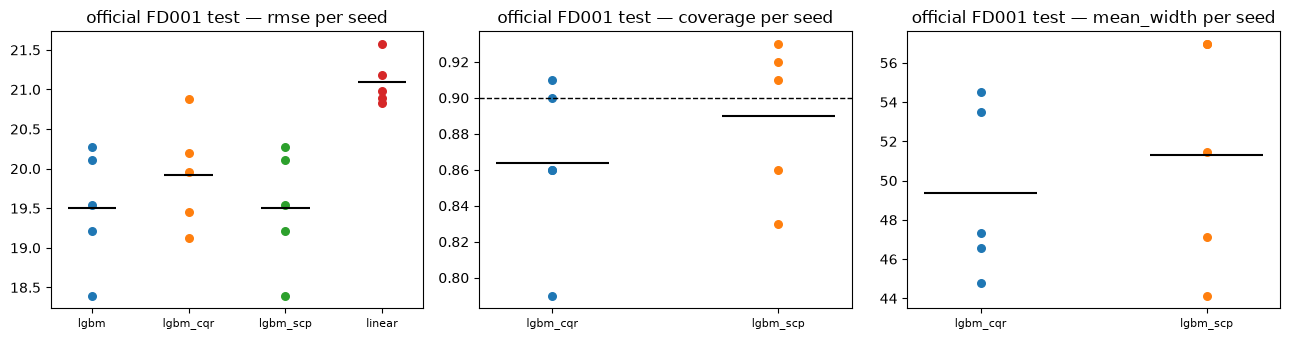

In [5]:
official = runs[runs["eval_set"] == "official"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ["rmse", "coverage", "mean_width"]):
    sub = official.dropna(subset=[metric])
    for i, (model, grp) in enumerate(sub.groupby("model")):
        ax.scatter([i] * len(grp), grp[metric], s=30, label=model)
        ax.hlines(grp[metric].mean(), i - 0.25, i + 0.25, color="k")
    ax.set_xticks(range(sub["model"].nunique()), sorted(sub["model"].unique()), fontsize=8)
    ax.set(title=f"official FD001 test — {metric} per seed")
    if metric == "coverage":
        ax.axhline(CONFIDENCE_LEVEL, color="k", ls="--", lw=1)
fig.tight_layout()
save(fig, "fd001_seed_variability.png")

**Interpretation.** Dots are seeds, the black tick is the mean. The spread between seeds is of the same
order as the difference between SCP and CQR, which is why the thesis protocol prescribes ten seeds and
paired statistical tests before claiming that one method is better.

In [6]:
logged = load_runs()
print(len(logged), "rows in results/runs.csv")
logged.sort_values(["model", "seed"]).reset_index(drop=True)

20 rows in results/runs.csv


,subset,model,seed,rmse,nasa_score,coverage,mean_width,n_test
0,FD001,lgbm,0,19.214,1387.64,NaN,NaN,100
1,FD001,lgbm,1,20.273,1787.54,NaN,NaN,100
2,FD001,lgbm,2,19.540,1857.75,NaN,NaN,100
3,FD001,lgbm,3,18.396,1117.45,NaN,NaN,100
4,FD001,lgbm,4,20.110,1816.24,NaN,NaN,100
5,FD001,lgbm_cqr,0,19.957,1471.98,0.86,47.306,100
6,FD001,lgbm_cqr,1,20.877,1686.27,0.91,54.529,100
7,FD001,lgbm_cqr,2,19.449,1490.00,0.90,53.517,100
8,FD001,lgbm_cqr,3,19.119,1465.36,0.86,46.576,100
9,FD001,lgbm_cqr,4,20.197,1798.94,0.79,44.798,100
